In [1]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [3]:
import matplotlib.pyplot as plt
import numpy as np

In [4]:
# Data path:
data_path = r"C:\Users\saiku\Project 2\PRCP-1001-RiceLeaf\Data"

In [5]:
# Data Preprocessing
datagen = ImageDataGenerator(
    rescale = 1./255,
    validation_split = 0.2
)

In [6]:
train_data = datagen.flow_from_directory(
    data_path,
    target_size = (224,224),
    batch_size = 8,
    class_mode = 'categorical',
    subset = 'training'
)

val_data = datagen.flow_from_directory(
    data_path,
    target_size = (224,224),
    batch_size = 8,
    class_mode = 'categorical',
    subset = 'validation'
)

Found 82 images belonging to 3 classes.
Found 19 images belonging to 3 classes.


In [7]:
# print class labels
print("Class Indices: ", train_data.class_indices)

Class Indices:  {'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}


In [8]:
# Build Model
model = Sequential()

model.add(Conv2D(16, (3,3), activation = 'relu', input_shape=(224,224,3)))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(32, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(Flatten())

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(3, activation='softmax'))

C:\Users\saiku\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
# compile model
model.compile(
    optimizer = 'adam',
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 32)        │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 43264)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │       2,768,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,792,739 (10.65 MB)

 Trainable params: 2,792,739 (10.65 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# train model
history = model.fit(
    train_data,
    validation_data = val_data,
    epochs = 20
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 403ms/step - accuracy: 0.4268 - loss: 1.3376 - val_accuracy: 0.3684 - val_loss: 1.0822
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 328ms/step - accuracy: 0.4024 - loss: 1.0888 - val_accuracy: 0.4211 - val_loss: 1.0226
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 340ms/step - accuracy: 0.5244 - loss: 1.0392 - val_accuracy: 0.4211 - val_loss: 0.9682
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 334ms/step - accuracy: 0.4634 - loss: 0.9749 - val_accuracy: 0.4737 - val_loss: 0.8825
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 323ms/step - accuracy: 0.4634 - loss: 0.9511 - val_accuracy: 0.4211 - val_loss: 0.8581
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 324ms/step - accuracy: 0.6341 - loss: 0.8635 - val_accuracy: 0.2632 - val_loss: 1.4376
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 310ms/step - accuracy: 0.6463 - loss: 0.7437 - val_accuracy: 0.4211 - val_loss: 1.4253
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 328ms/step - accuracy: 0.6829 - loss: 0.6235 - val_accuracy: 0.

In [12]:
# Accuracy
loss, accuracy = model.evaluate(val_data)
print("Validation Accuracy: " ,accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 173ms/step - accuracy: 0.5789 - loss: 1.4077
Validation Accuracy:  0.5789473652839661


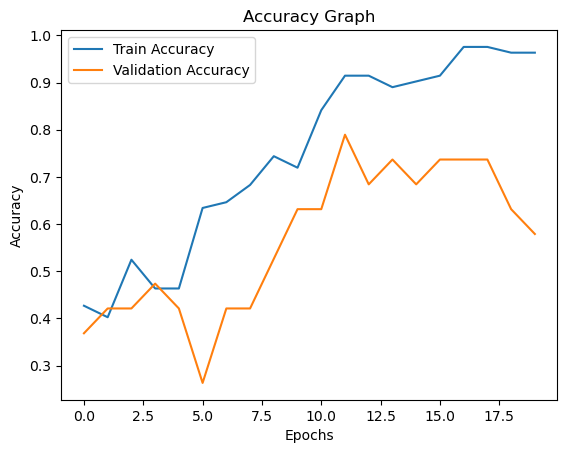

In [13]:
# accuracy graphs:
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label = 'Validation Accuracy')
plt.title('Accuracy Graph')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

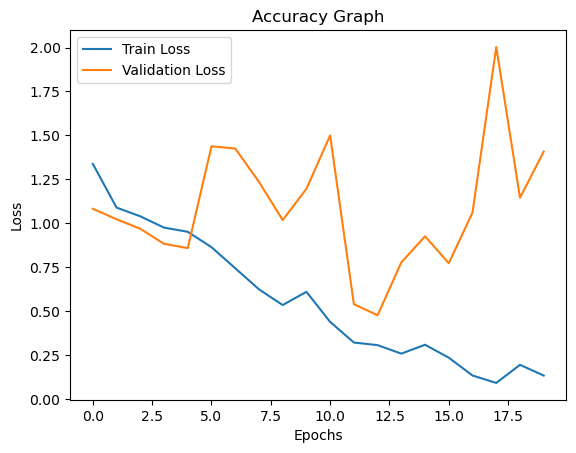

In [14]:
# loss graphs:
plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label = 'Validation Loss')
plt.title('Accuracy Graph')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()